# 01 - Analyse exploratoire (EDA)

Exploration du German Credit Data : qualite des donnees, distribution de la cible et lien entre chaque variable et le risque de defaut.

In [1]:
from pathlib import Path

# Le notebook s'execute depuis notebooks/ (Jupyter / VS Code) ou depuis la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data" / "raw" / "german_credit_data_updated.csv", index_col=0)
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,49,male,1,own,little,NaN,2096,12,education,1
3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,53,male,2,free,little,little,4870,24,car,2


## Structure et qualite des donnees

In [2]:
print(f"{df.shape[0]} lignes, {df.shape[1]} colonnes")
print(f"Doublons : {df.duplicated().sum()}")
df.info()

954 lignes, 10 colonnes
Doublons : 0
<class 'pandas.DataFrame'>
RangeIndex: 954 entries, 0 to 953
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               954 non-null    int64
 1   Sex               954 non-null    str  
 2   Job               954 non-null    int64
 3   Housing           954 non-null    str  
 4   Saving accounts   779 non-null    str  
 5   Checking account  576 non-null    str  
 6   Credit amount     954 non-null    int64
 7   Duration          954 non-null    int64
 8   Purpose           954 non-null    str  
 9   Credit Risk       954 non-null    int64
dtypes: int64(5), str(5)
memory usage: 74.7 KB


In [3]:
# Valeurs manquantes : absence de compte (remplacees par "none" dans preprocess.py)
df.isna().sum()[lambda s: s > 0]

Saving accounts     175
Checking account    378
dtype: int64

In [4]:
df.describe()

,Age,Job,Credit amount,Duration,Credit Risk
count,954.000000,954.000000,954.000000,954.000000,954.000000
mean,35.501048,1.909853,3279.112159,20.780922,1.302935
std,11.379668,0.649681,2853.315158,12.046483,0.459768
min,19.000000,0.000000,250.000000,4.000000,1.000000
25%,27.000000,2.000000,1360.250000,12.000000,1.000000
50%,33.000000,2.000000,2302.500000,18.000000,1.000000
75%,42.000000,2.000000,3975.250000,24.000000,2.000000
max,75.000000,3.000000,18424.000000,72.000000,2.000000


## Variable cible

`Credit Risk` : 1 = bon payeur, 2 = defaut. Elle est remappee en 0 / 1 dans `features.py`.

In [5]:
df["default"] = (df["Credit Risk"] == 2).astype(int)
print(df["Credit Risk"].value_counts())
print(f"\nTaux de defaut : {df['default'].mean():.1%}")

Credit Risk
1    665
2    289
Name: count, dtype: int64

Taux de defaut : 30.3%


## Variables numeriques

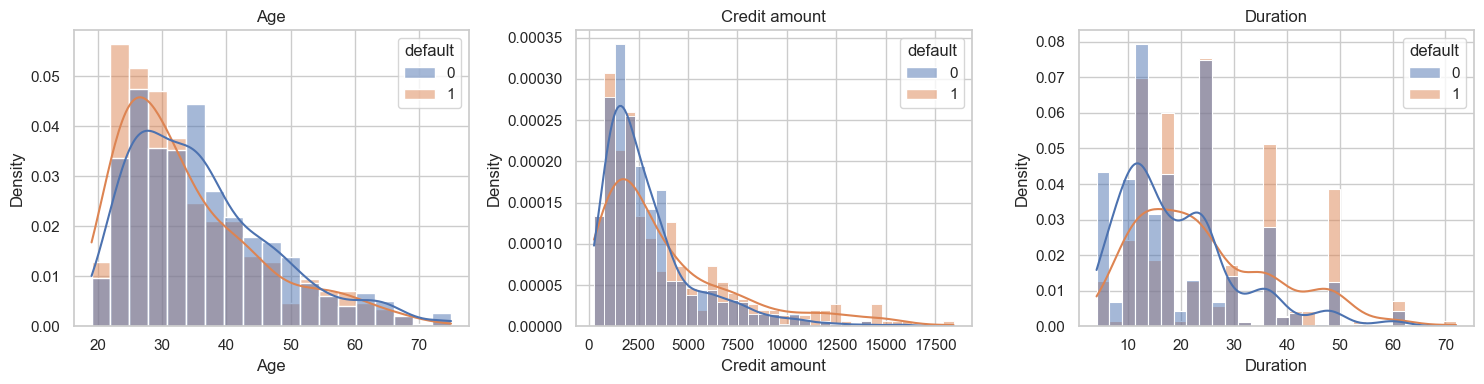

In [6]:
numeric_cols = ["Age", "Credit amount", "Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, hue="default", stat="density", common_norm=False, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [7]:
# Mediane par classe : les defauts concernent des credits plus longs et plus eleves
df.groupby("default")[numeric_cols].median()

,Age,Credit amount,Duration
default,,,
0,34.0,2241.0,18.0
1,31.0,2579.0,24.0


## Variables categorielles : taux de defaut par modalite

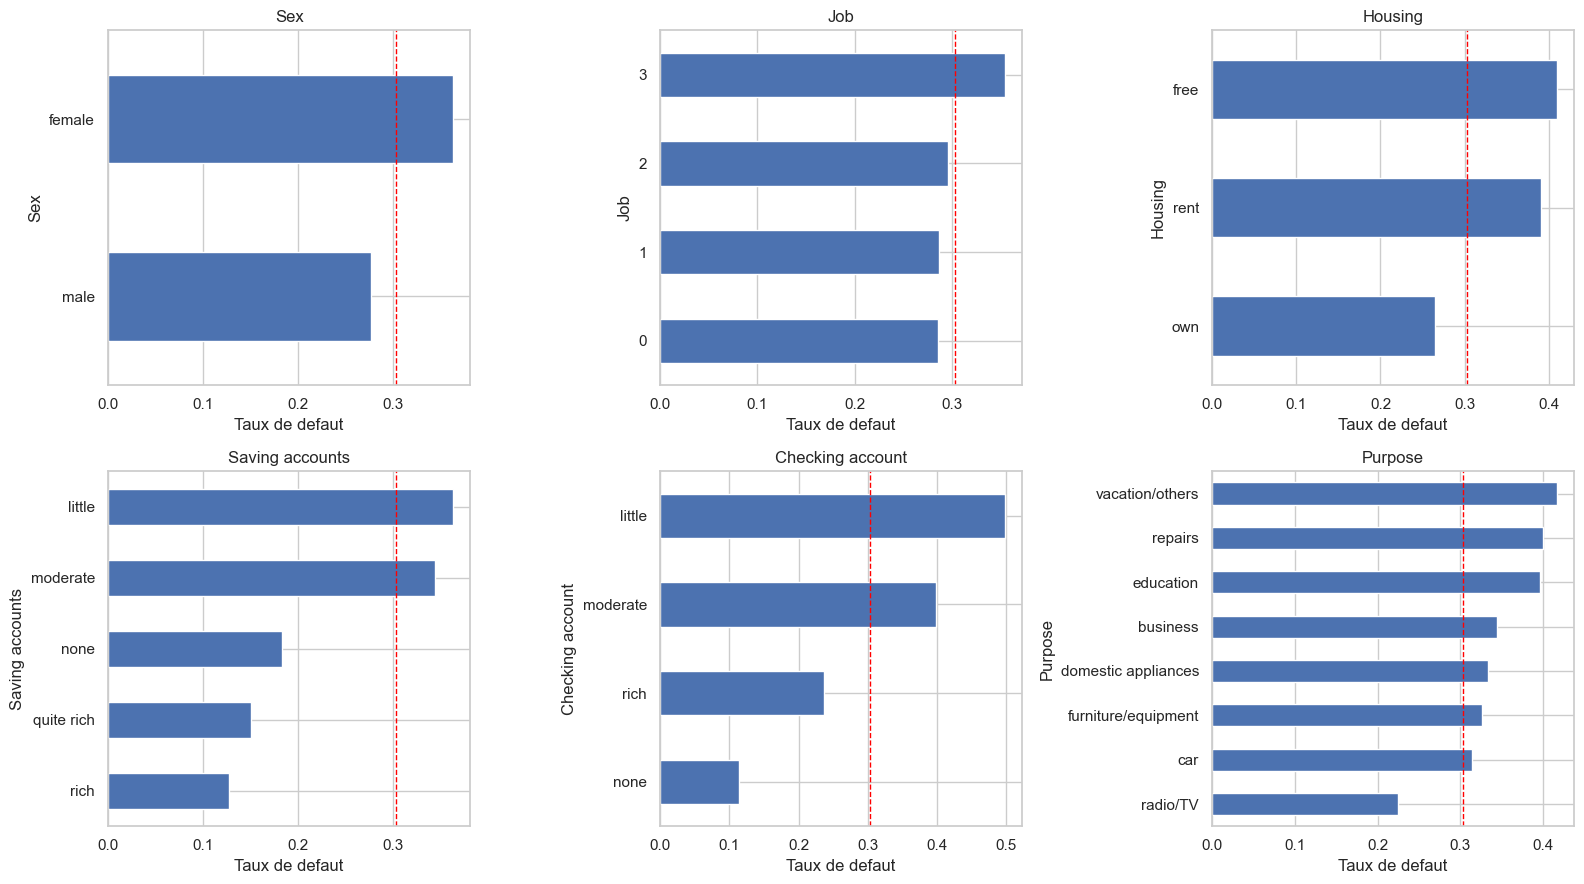

In [8]:
categorical_cols = ["Sex", "Job", "Housing", "Saving accounts", "Checking account", "Purpose"]
df_cat = df.fillna({"Saving accounts": "none", "Checking account": "none"})

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), categorical_cols):
    rates = df_cat.groupby(col)["default"].mean().sort_values()
    rates.plot.barh(ax=ax)
    ax.axvline(df["default"].mean(), color="red", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Taux de defaut")
plt.tight_layout()
plt.show()

## Correlations

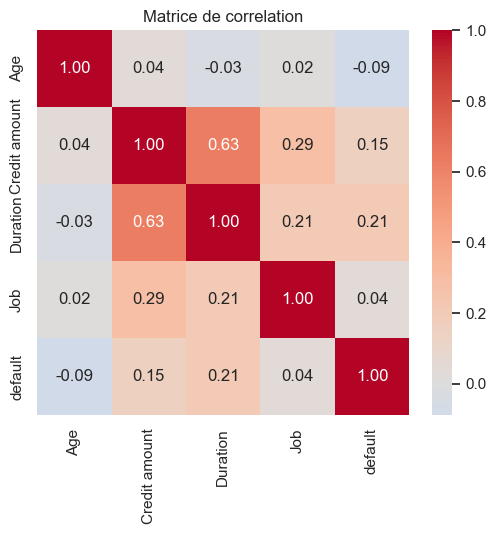

In [9]:
corr = df[numeric_cols + ["Job", "default"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de correlation")
plt.show()

## Conclusions

- Environ 30 % de defauts : classes desequilibrees, d'ou `class_weight="balanced"` et le suivi de l'AUC plutot que de l'accuracy.
- Les valeurs manquantes de `Saving accounts` / `Checking account` signifient l'absence de compte : elles sont gardees comme modalite `none`.
- `Duration` et `Credit amount` sont fortement correles et plus eleves chez les defauts ; `Checking account` est la variable categorielle la plus discriminante.